# H&M Personalized Fashion Recommendations — プロジェクトレポート要約

EDA(仮説検証) → 候補生成設計 → パイプライン構築 → 実験の反復(成功/失敗) → 本日(多週検証手法)までの
全体の流れを発表資料用に可視化したノートブック。元の根拠は `00_md/hypothesis_driven_design.md`、
`00_md/pipeline_build_log.md`、`experiment_log.csv`。

すべての図は `02_output/report_figures/` にPNGとしても保存されており、PPTにそのまま貼り付けられる
(`02_output/` はGit管理外 — CLAUDE.md参照)。

In [1]:
import os
import sys

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

sys.path.append(os.path.abspath("."))
from common import DATA_DIR, TRANS_LITE_PATH, EXPERIMENT_LOG_PATH, MODELS_DIR, get_con

FIG_DIR = os.path.join("..", "02_output", "report_figures")
REPORT_DATA_DIR = os.path.join("..", "02_output", "report_data")
os.makedirs(FIG_DIR, exist_ok=True)

# --- dataviz パレット(skill references/palette.md) ---
CAT = {
    "blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "yellow": "#eda100",
    "magenta": "#e87ba4", "green": "#008300", "violet": "#4a3aa7", "red": "#e34948",
}
SEQ_BLUE = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
DIVERGE_POS, DIVERGE_NEG, DIVERGE_MID = CAT["blue"], CAT["red"], "#f0efec"
TEXT_PRIMARY, TEXT_SECONDARY, GRID = "#1a1a1a", "#595959", "#e4e2dd"

plt.rcParams.update({
    "font.family": "Hiragino Sans", "axes.unicode_minus": False,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": GRID, "axes.labelcolor": TEXT_SECONDARY,
    "text.color": TEXT_PRIMARY, "xtick.color": TEXT_SECONDARY, "ytick.color": TEXT_SECONDARY,
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GRID, "grid.linewidth": 0.8,
    "savefig.dpi": 150, "savefig.bbox": "tight",
})

def savefig(fig, name):
    path = os.path.join(FIG_DIR, name)
    fig.savefig(path)
    print(f"saved: {path}")

con = get_con()
print("ready")

ready


---
# 1. EDA — 仮説検証(H1〜H11)

11個の仮説をduckdbで全取引3,178万件に対して直接集計し、採用/棄却を判定した
(`00_md/hypothesis_driven_design.md`)。採用した仮説は候補生成/特徴量設計にそのまま反映した。

## H1 — 自己リピート(同じ商品/色違いの再購入)傾向
**採用**: 同一article再購入14.1% + 同一product_code色違い9.1% = 23.2%がリピート性。
残り76.8%は完全新規商品 → 自己リピートだけでは候補の大半を埋められないという設計根拠。

saved: ../02_output/report_figures/h1_repeat_breakdown.png


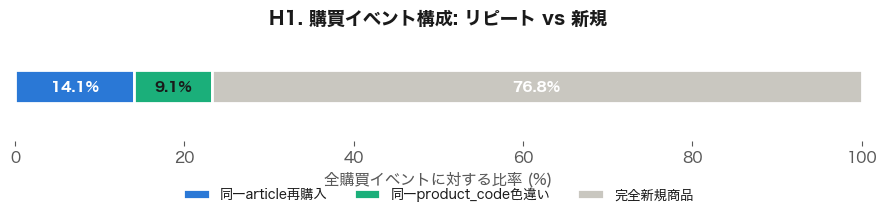

In [2]:
h1 = pd.DataFrame({
    "segment": ["同一article再購入", "同一product_code色違い", "完全新規商品"],
    "share": [14.1, 9.1, 76.8],
})
colors = [CAT["blue"], CAT["aqua"], "#c9c7c0"]

fig, ax = plt.subplots(figsize=(9, 2.6))
left = 0
bars = []
for (_, row), c in zip(h1.iterrows(), colors):
    b = ax.barh(0, row["share"], left=left, color=c, height=0.55,
                edgecolor="white", linewidth=2, label=row["segment"])
    bars.append(b)
    ax.text(left + row["share"] / 2, 0, f'{row["share"]}%',
            ha="center", va="center", fontsize=10,
            color="white" if row["share"] > 10 else TEXT_PRIMARY, fontweight="bold")
    left += row["share"]
ax.set_xlim(0, 100)
ax.set_ylim(-0.9, 0.9)
ax.set_yticks([])
ax.set_xlabel("全購買イベントに対する比率 (%)")
ax.set_title("H1. 購買イベント構成: リピート vs 新規")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.32), ncol=3, frameon=False, fontsize=9.5)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
fig.tight_layout()
savefig(fig, "h1_repeat_breakdown.png")
plt.show()

## H2 — カテゴリ偏向購入傾向
**H2a/H2b 採用(強い)、H2c 棄却(弱い)**: 特定カテゴリを3回以上購入した顧客の該当カテゴリ
購入比率が母集団平均の何倍かを比較。Menswear 4.8倍、Baby/Children 9.6倍と強いシグナル、
Ladieswearは1.1倍で母集団の大半が既に購入者のため判別力が弱い。

saved: ../02_output/report_figures/h2_category_affinity.png


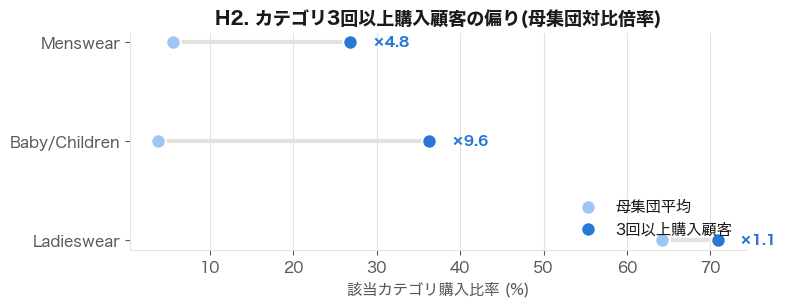

In [3]:
h2 = pd.DataFrame({
    "category": ["Menswear", "Baby/Children", "Ladieswear"],
    "population_share": [5.6, 3.8, 64.2],
    "heavy_buyer_share": [26.8, 36.3, 70.9],
    "multiplier": [4.8, 9.6, 1.1],
})

fig, ax = plt.subplots(figsize=(8, 3.2))
y = np.arange(len(h2))[::-1]
for yi, (_, row) in zip(y, h2.iterrows()):
    ax.plot([row.population_share, row.heavy_buyer_share], [yi, yi],
            color=GRID, linewidth=3, zorder=1)
    ax.scatter(row.population_share, yi, color=SEQ_BLUE[1], s=110, zorder=2,
                edgecolor="white", linewidth=1.5, label="母集団平均" if yi == y[0] else None)
    ax.scatter(row.heavy_buyer_share, yi, color=CAT["blue"], s=110, zorder=2,
                edgecolor="white", linewidth=1.5, label="3回以上購入顧客" if yi == y[0] else None)
    ax.text(row.heavy_buyer_share + 2.5, yi, f"×{row.multiplier}", va="center",
            fontsize=10, fontweight="bold", color=CAT["blue"])
ax.set_yticks(y)
ax.set_yticklabels(h2.category)
ax.set_xlabel("該当カテゴリ購入比率 (%)")
ax.set_title("H2. カテゴリ3回以上購入顧客の偏り(母集団対比倍率)")
ax.legend(loc="lower right", frameon=False)
ax.grid(axis="x")
fig.tight_layout()
savefig(fig, "h2_category_affinity.png")
plt.show()

## H4 — 季節性・トレンドに強く左右される(ファストファッション)
**採用(強い)**: 週次取引量に明確なスパイク(ブラックフライデーなど)とCOVID-19ロックダウン期
(2020年3〜4月)の明確な急減が存在。トレンド特徴量は必須、COVID区間はレジームシフトとして別扱い。

saved: ../02_output/report_figures/h4_weekly_trend.png


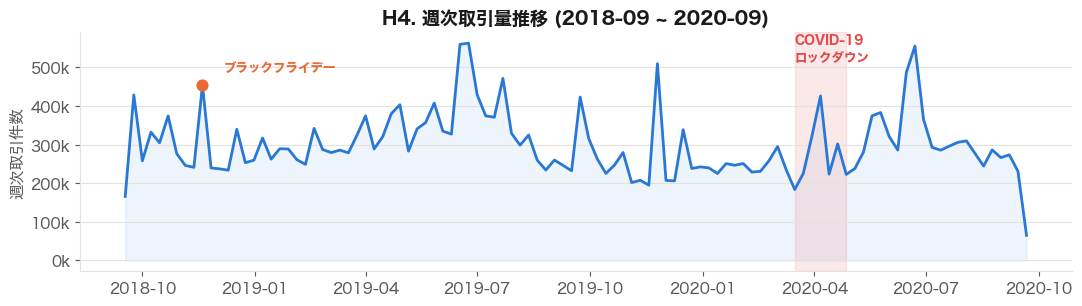

In [4]:
weekly = con.execute("""
    SELECT DATE_TRUNC('week', t_dat)::DATE AS wk, COUNT(*) AS cnt
    FROM trans GROUP BY wk ORDER BY wk
""").df()

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(weekly.wk, weekly.cnt, color=CAT["blue"], linewidth=2)
ax.fill_between(weekly.wk, weekly.cnt, color=CAT["blue"], alpha=0.08)

covid = weekly[(weekly.wk >= "2020-03-16") & (weekly.wk <= "2020-04-27")]
ax.axvspan(covid.wk.min(), covid.wk.max(), color=CAT["red"], alpha=0.12)
ax.text(covid.wk.min(), weekly.cnt.max() * 0.92, "COVID-19\nロックダウン", color=CAT["red"],
        fontsize=9, fontweight="bold")

bf = weekly[(weekly.wk >= "2018-11-12") & (weekly.wk <= "2018-11-26")]
if len(bf):
    peak = bf.loc[bf.cnt.idxmax()]
    ax.scatter([peak.wk], [peak.cnt], color=CAT["orange"], s=60, zorder=3)
    ax.annotate("ブラックフライデー", xy=(peak.wk, peak.cnt), xytext=(15, 10),
                textcoords="offset points", color=CAT["orange"], fontsize=9, fontweight="bold")

ax.set_title("H4. 週次取引量推移 (2018-09 ~ 2020-09)")
ax.set_ylabel("週次取引件数")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1000:.0f}k"))
ax.grid(axis="y")
fig.tight_layout()
savefig(fig, "h4_weekly_trend.png")
plt.show()

## H5/H7 — 個人予算帯の存在 + オフライン/オンライン購入パターンの違い
**両方採用**: 顧客別価格変動係数(CV)が母集団CVより小さい(個人予算帯の存在)。
オンラインはオフライン対比、平均単価+30%、バスケット合計額+108%、購入点数+60%。

saved: ../02_output/report_figures/h5_h7_pricing_channel.png


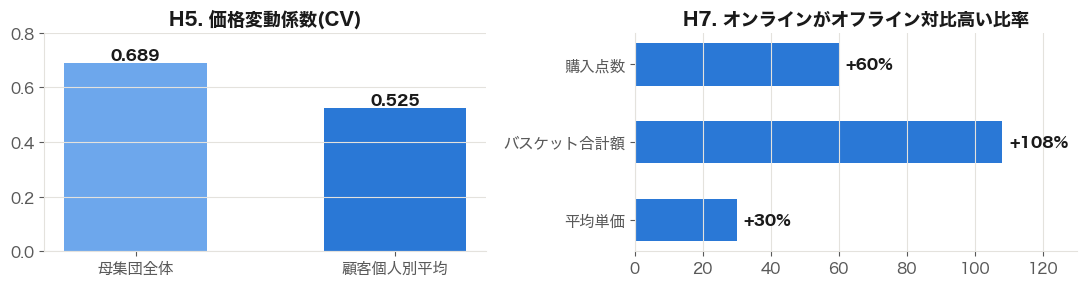

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3))

ax = axes[0]
cv = pd.DataFrame({"group": ["母集団全体", "顧客個人別平均"], "cv": [0.689, 0.525]})
bars = ax.bar(cv.group, cv.cv, color=[SEQ_BLUE[2], CAT["blue"]], width=0.55)
for b, v in zip(bars, cv.cv):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.3f}", ha="center", fontweight="bold")
ax.set_title("H5. 価格変動係数(CV)")
ax.set_ylim(0, 0.8)
ax.grid(axis="y")

ax = axes[1]
ch = pd.DataFrame({
    "metric": ["平均単価", "バスケット合計額", "購入点数"],
    "online_vs_store": [30, 108, 60],
})
bars = ax.barh(ch.metric, ch.online_vs_store, color=CAT["blue"], height=0.55)
for b, v in zip(bars, ch.online_vs_store):
    ax.text(v + 2, b.get_y() + b.get_height() / 2, f"+{v}%", va="center", fontweight="bold")
ax.set_title("H7. オンラインがオフライン対比高い比率")
ax.set_xlim(0, 130)
ax.grid(axis="x")
fig.tight_layout()
savefig(fig, "h5_h7_pricing_channel.png")
plt.show()

## H9 — コールドスタート顧客比率
**採用(設計に直結)**: 学習期間購入0件0.7% + 1件9.6% = 10.3%が実質コールドスタート。
10回以上購入の顧客は49.3% → 人気度フォールバックと個人化モデルの二元化設計の根拠。

saved: ../02_output/report_figures/h9_cold_start.png


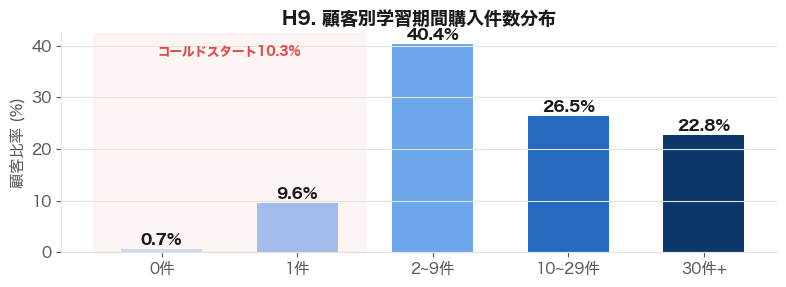

In [6]:
cold = pd.DataFrame({
    "bucket": ["0件", "1件", "2~9件", "10~29件", "30件+"],
    "share": [0.7, 9.6, 40.4, 26.5, 22.8],
})
colors = [SEQ_BLUE[i] for i in [0, 1, 2, 4, 6]]
fig, ax = plt.subplots(figsize=(8, 3))
bars = ax.bar(cold.bucket, cold.share, color=colors, width=0.6)
for b, v in zip(bars, cold.share):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.7, f"{v}%", ha="center", fontweight="bold")
ax.axvspan(-0.5, 1.5, color=CAT["red"], alpha=0.06)
ax.text(0.5, 38, "コールドスタート10.3%", ha="center", color=CAT["red"], fontsize=9, fontweight="bold")
ax.set_title("H9. 顧客別学習期間購入件数分布")
ax.set_ylabel("顧客比率 (%)")
ax.grid(axis="y")
fig.tight_layout()
savefig(fig, "h9_cold_start.png")
plt.show()

## H10 — 商品ライフサイクル(死に筋在庫)仮説
**採用**: 直近12週間売れていない商品が全カタログの60.8%。人気度ベースの候補は直近の販売
実績でフィルタすべきことを示唆。

saved: ../02_output/report_figures/h10_dead_stock.png


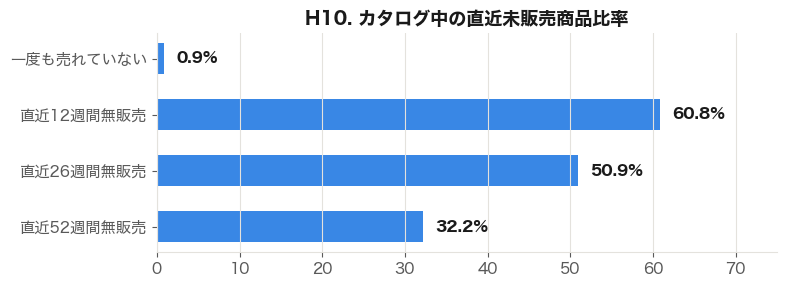

In [7]:
dead = pd.DataFrame({
    "window": ["一度も売れていない", "直近12週間無販売", "直近26週間無販売", "直近52週間無販売"],
    "share": [0.9, 60.8, 50.9, 32.2],
})
fig, ax = plt.subplots(figsize=(8, 3))
bars = ax.barh(dead.window[::-1], dead.share[::-1], color=SEQ_BLUE[3], height=0.55)
for b, v in zip(bars, dead.share[::-1]):
    ax.text(v + 1.5, b.get_y() + b.get_height() / 2, f"{v}%", va="center", fontweight="bold")
ax.set_xlim(0, 75)
ax.set_title("H10. カタログ中の直近未販売商品比率")
ax.grid(axis="x")
fig.tight_layout()
savefig(fig, "h10_dead_stock.png")
plt.show()

## H11 — 給料日効果
**採用**: 月末(22〜29日)にかけて取引量指数が106〜125と高く、5〜15日は85〜92と低い。
スウェーデンの一般的な給料日(月末近辺)と一致。

saved: ../02_output/report_figures/h11_payday_effect.png


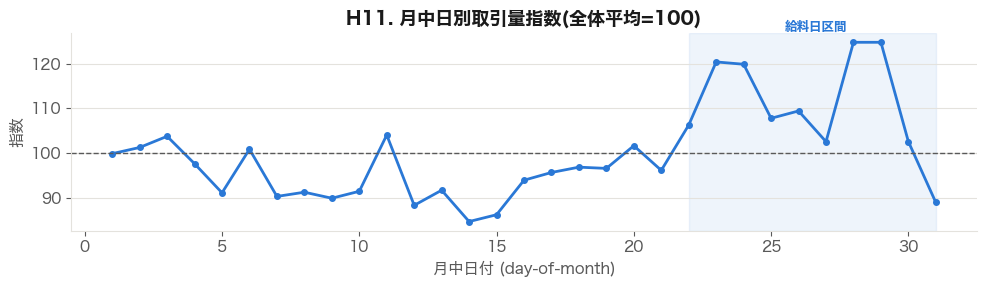

In [8]:
dom = con.execute("""
    WITH daily AS (SELECT t_dat, COUNT(*) AS cnt FROM trans GROUP BY t_dat)
    SELECT EXTRACT(day FROM t_dat)::INTEGER AS dom, AVG(cnt) AS avg_cnt
    FROM daily GROUP BY dom ORDER BY dom
""").df()
dom["index"] = dom.avg_cnt / dom.avg_cnt.mean() * 100

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(dom.dom, dom["index"], color=CAT["blue"], linewidth=2, marker="o", markersize=4)
ax.axhline(100, color=TEXT_SECONDARY, linewidth=1, linestyle="--")
ax.axvspan(22, dom.dom.max(), color=CAT["blue"], alpha=0.08)
ax.text(25.5, dom["index"].max() * 1.02, "給料日区間", color=CAT["blue"], fontsize=9, fontweight="bold")
ax.set_title("H11. 月中日別取引量指数(全体平均=100)")
ax.set_xlabel("月中日付 (day-of-month)")
ax.set_ylabel("指数")
ax.grid(axis="y")
fig.tight_layout()
savefig(fig, "h11_payday_effect.png")
plt.show()

---
# 2. 候補生成(Stage 1) — ソース別性能

6個の候補ソースを単独で監査(`03_candidate_generation.ipynb`、直近7日ホールドアウト基準)。
自己リピート(A)が最も強いが単独ではRecall@12 0.04程度 → 複数ソースを組み合わせると上限が上がる
(6ソース結合時のRecall@12上限0.093、単一ソース対比2倍以上)。

saved: ../02_output/report_figures/candidate_source_comparison.png


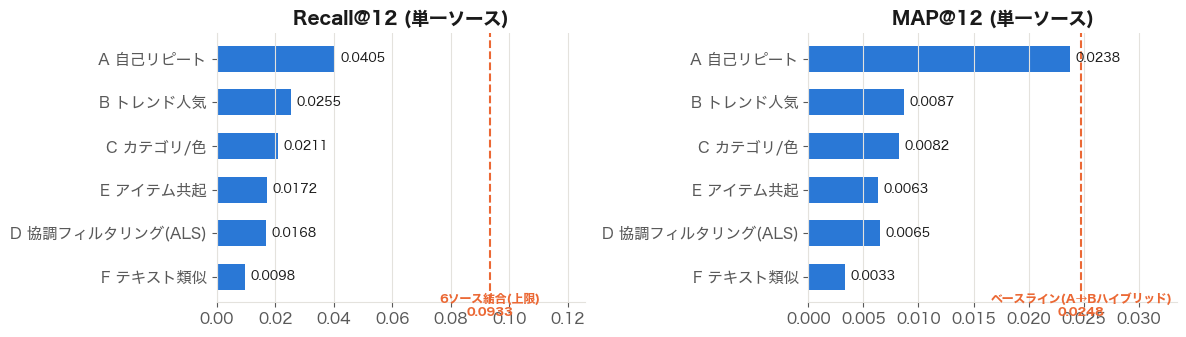

In [9]:
sources = pd.DataFrame({
    "source": ["A 自己リピート", "B トレンド人気", "C カテゴリ/色", "D 協調フィルタリング(ALS)",
               "E アイテム共起", "F テキスト類似"],
    "recall12": [0.0405, 0.0255, 0.0211, 0.0168, 0.0172, 0.0098],
    "map12": [0.0238, 0.0087, 0.0082, 0.0065, 0.0063, 0.0033],
}).sort_values("recall12")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, col, title, ref_name, ref_val in [
    (axes[0], "recall12", "Recall@12 (単一ソース)", "6ソース結合(上限)", 0.0933),
    (axes[1], "map12", "MAP@12 (単一ソース)", "ベースライン(A→Bハイブリッド)", 0.0248),
]:
    bars = ax.barh(sources.source, sources[col], color=CAT["blue"], height=0.6)
    for b, v in zip(bars, sources[col]):
        ax.text(v + ref_val * 0.02, b.get_y() + b.get_height() / 2, f"{v:.4f}",
                va="center", fontsize=9)
    ax.axvline(ref_val, color=CAT["orange"], linestyle="--", linewidth=1.5)
    ax.text(ref_val, -0.9, f"{ref_name}\n{ref_val}", color=CAT["orange"], fontsize=8.5,
            ha="center", fontweight="bold")
    ax.set_title(title)
    ax.set_xlim(0, ref_val * 1.35)
    ax.grid(axis="x")
fig.tight_layout()
savefig(fig, "candidate_source_comparison.png")
plt.show()

---
# 3. パイプライン進行経過 — backtest vs 実際のLB

`experiment_log.csv`の全rankerの実験を時系列で並べたもの。baseline対比2段構成(候補生成+LGBMRanker)
の導入が最大の飛躍(+26%)で、以降の候補追加/ハイパーパラメータチューニングは収穫逓減区間。
**backtest(オレンジ点線)が改善しても実際のLB(棒)が常について来るとは限らない** — これが本日
多週検証手法を作った理由。

saved: ../02_output/report_figures/pipeline_evolution_timeline.png


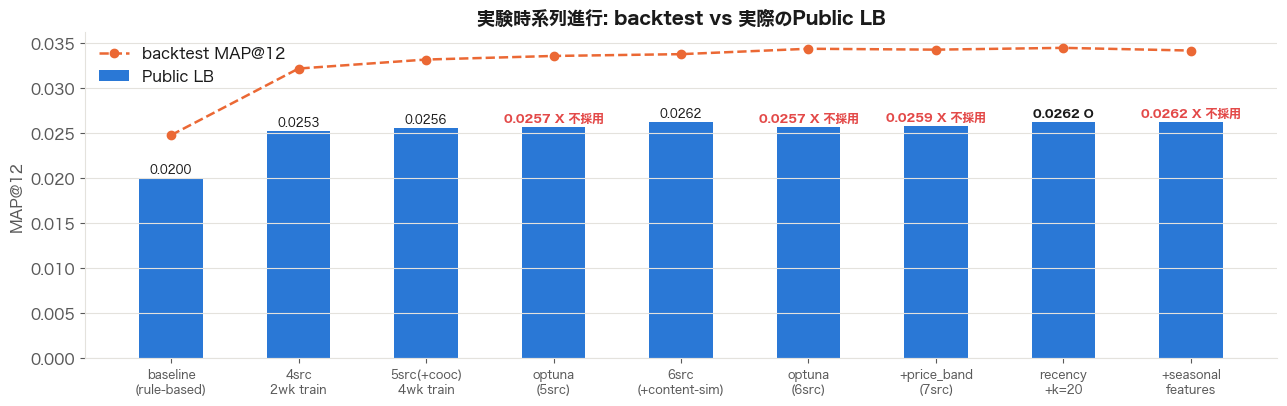

In [10]:
log = pd.read_csv(EXPERIMENT_LOG_PATH)
log = log[log["run_id"].str.contains("ranker") | (log["run_id"] == "run_20260807_1631")].copy()
log = log[~log["run_id"].str.contains("classifier")]
log["ts"] = pd.to_datetime(log["timestamp"], format="%Y%m%d_%H%M")
log = log.sort_values("ts").reset_index(drop=True)

label_map = {
    "run_20260807_1631": "baseline\n(rule-based)",
    "run_20260813_1418_ranker": "4src\n2wk train",
    "run_20260813_1956_ranker": "5src(+cooc)\n4wk train",
    "run_20260814_0833_ranker_optuna": "optuna\n(5src)",
    "run_20260901_0953_ranker": "6src\n(+content-sim)",
    "run_20260901_1232_ranker_optuna": "optuna\n(6src)",
    "run_20260901_1508_ranker": "+price_band\n(7src)",
    "run_20260906_0924_ranker": "recency\n+k=20",
    "run_20260917_2337_ranker": "+seasonal\nfeatures",
}
log["label"] = log["run_id"].map(label_map).fillna(log["run_id"])
log["public_lb"] = pd.to_numeric(log["public_lb"], errors="coerce")

fig, ax = plt.subplots(figsize=(13, 4.2))
x = np.arange(len(log))
bars = ax.bar(x, log["public_lb"], color=CAT["blue"], width=0.5, label="Public LB")
ax.plot(x, log["cv_score"], color=CAT["orange"], marker="o", markersize=6,
        linestyle="--", linewidth=1.8, label="backtest MAP@12")

reject_runs = {"run_20260814_0833_ranker_optuna", "run_20260901_1232_ranker_optuna",
               "run_20260901_1508_ranker", "run_20260917_2337_ranker"}
for xi, rid, v in zip(x, log["run_id"], log["public_lb"]):
    if pd.notna(v):
        color = CAT["red"] if rid in reject_runs else TEXT_PRIMARY
        marker = " X 不採用" if rid in reject_runs else (" O" if rid == "run_20260906_0924_ranker" else "")
        ax.text(xi, v + 0.0006, f"{v:.4f}{marker}", ha="center", fontsize=8.5, color=color,
                fontweight="bold" if marker else "normal")

ax.set_xticks(x)
ax.set_xticklabels(log["label"], fontsize=8.5)
ax.set_ylabel("MAP@12")
ax.set_title("実験時系列進行: backtest vs 実際のPublic LB")
ax.legend(loc="upper left", frameon=False)
ax.grid(axis="y")
fig.tight_layout()
savefig(fig, "pipeline_evolution_timeline.png")
plt.show()

---
# 4. 本日の作業 — 多週検証手法

単一val週だけを見るbacktestは、optuna・price_band実験で「backtestは改善、実際のLBは悪化」を
一度も検出できなかった。再学習せず**学習に使っていない過去3週**で既存モデルを再採点する
`multi_week_eval.py`を作って検証した(`08_multi_week_backtest.ipynb`)。

saved: ../02_output/report_figures/multiweek_eval_optuna_0906.png


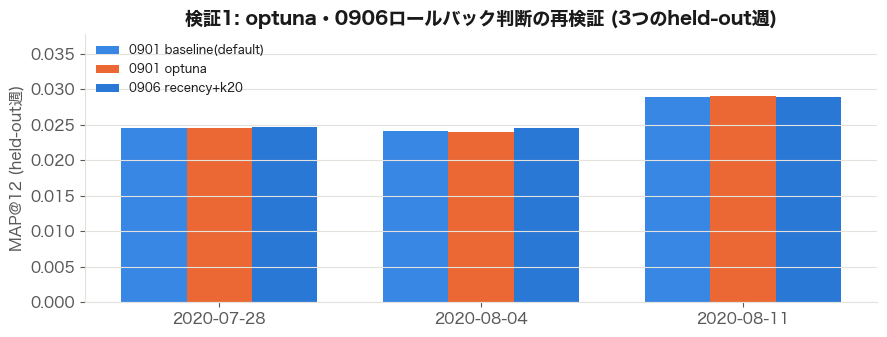

3週平均:
model
0901_baseline_default_params    0.02589
0901_optuna_params              0.02592
0906_recency_k20                0.02605
dtype: float64


In [11]:
mw1 = pd.read_csv(os.path.join(REPORT_DATA_DIR, "multi_week_eval_optuna_0906_result.csv"))
pivot1 = mw1.pivot(index="cutoff", columns="model", values="map12")
pivot1 = pivot1[["0901_baseline_default_params", "0901_optuna_params", "0906_recency_k20"]]

fig, ax = plt.subplots(figsize=(9, 3.5))
x = np.arange(len(pivot1))
w = 0.25
colors = [SEQ_BLUE[3], CAT["orange"], CAT["blue"]]
labels = ["0901 baseline(default)", "0901 optuna", "0906 recency+k20"]
for i, (col, lab, c) in enumerate(zip(pivot1.columns, labels, colors)):
    ax.bar(x + (i - 1) * w, pivot1[col], width=w, color=c, label=lab)
ax.set_xticks(x)
ax.set_xticklabels(pivot1.index)
ax.set_ylabel("MAP@12 (held-out週)")
ax.set_title("検証1: optuna・0906ロールバック判断の再検証 (3つのheld-out週)")
ax.set_ylim(0, pivot1.to_numpy().max() * 1.3)
ax.legend(loc="upper left", frameon=False, fontsize=8.5)
ax.grid(axis="y")
fig.tight_layout()
savefig(fig, "multiweek_eval_optuna_0906.png")
plt.show()

print("3週平均:")
print(pivot1.mean().round(5))

**結論**: optunaは3週平均でbaselineとほぼ同値(単一週で見られた大きな改善は再現されず)。
0906(recency+k拡張)は3週中2週で優勢 → 実際のLBの「ほぼ横ばい」という結果と整合。

## 季節性特徴量追加実験 — 「多週検証でも検出できなかった」事例

アイテム/カテゴリ単位の「昨年同週販売量」特徴量4つを追加。3つのheld-out週**すべて**で
0906より一貫して優勢だったが、実際の提出結果は分かれた — 本日得た最も重要な方法論的教訓。

saved: ../02_output/report_figures/seasonal_feature_saga.png


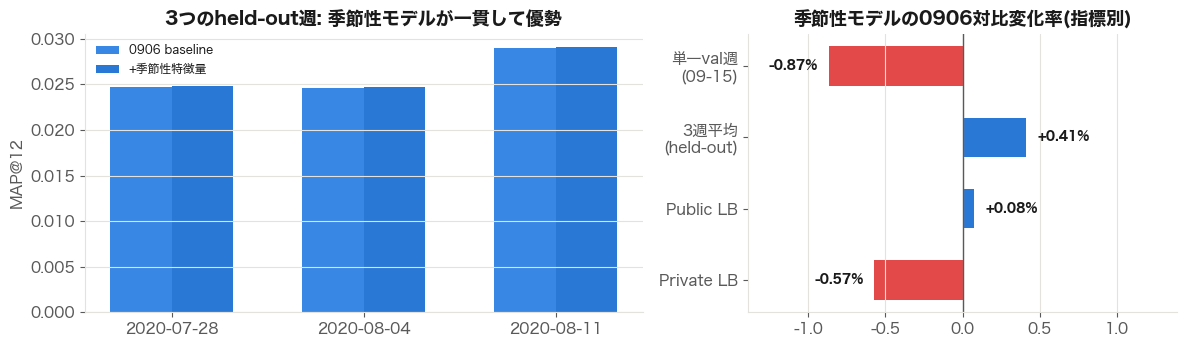

In [12]:
mw2 = pd.read_csv(os.path.join(REPORT_DATA_DIR, "multi_week_eval_seasonal_result.csv"))
pivot2 = mw2.pivot(index="cutoff", columns="model", values="map12")[["0906_baseline", "0917_seasonal"]]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1.3, 1]})

ax = axes[0]
x = np.arange(len(pivot2))
w = 0.32
ax.bar(x - w / 2, pivot2["0906_baseline"], width=w, color=SEQ_BLUE[3], label="0906 baseline")
ax.bar(x + w / 2, pivot2["0917_seasonal"], width=w, color=CAT["blue"], label="+季節性特徴量")
ax.set_xticks(x)
ax.set_xticklabels(pivot2.index)
ax.set_title("3つのheld-out週: 季節性モデルが一貫して優勢")
ax.set_ylabel("MAP@12")
ax.legend(loc="upper left", frameon=False, fontsize=8.5)
ax.grid(axis="y")

ax = axes[1]
metrics = pd.DataFrame({
    "metric": ["単一val週\n(09-15)", "3週平均\n(held-out)", "Public LB", "Private LB"],
    "0906": [0.0345, pivot2["0906_baseline"].mean(), 0.02621, 0.02620],
    "seasonal": [0.0342, pivot2["0917_seasonal"].mean(), 0.02623, 0.02605],
})
metrics["delta_pct"] = (metrics["seasonal"] / metrics["0906"] - 1) * 100
colors = [DIVERGE_POS if d >= 0 else DIVERGE_NEG for d in metrics["delta_pct"]]
bars = ax.barh(metrics["metric"][::-1], metrics["delta_pct"][::-1], color=colors[::-1], height=0.55)
ax.axvline(0, color=TEXT_SECONDARY, linewidth=1)
span = metrics["delta_pct"].abs().max()
ax.set_xlim(-span * 1.6, span * 1.6)
for b, v in zip(bars, metrics["delta_pct"][::-1]):
    off = span * 0.08
    ax.text(v + (off if v >= 0 else -off), b.get_y() + b.get_height() / 2, f"{v:+.2f}%",
            va="center", ha="left" if v >= 0 else "right", fontsize=9, fontweight="bold")
ax.set_title("季節性モデルの0906対比変化率(指標別)")
ax.grid(axis="x")
fig.tight_layout()
savefig(fig, "seasonal_feature_saga.png")
plt.show()

**教訓**: 単一val週はむしろ季節性モデルを悪く評価し(過小評価)、3週held-outは一貫して
良く評価した(過大評価の方向ではなかったが、Private LB悪化を検出できず)。Public LBは僅かに改善、
**Private LBは明確に悪化**(-0.00015、歴代最高記録対比で下落)。3週すべてが2020年7〜8月に集中しており
「複数週」ではあったが「複数季節」ではなかったことが限界と推定される → 06のモデルは0906のまま維持。

---
# 5. 現行プロダクションモデル(0906)の特徴量重要度

`model_20260906_0924_ranker.pkl`(LightGBM LGBMRanker)のgain基準重要度トップ15。

saved: ../02_output/report_figures/feature_importance_0906.png


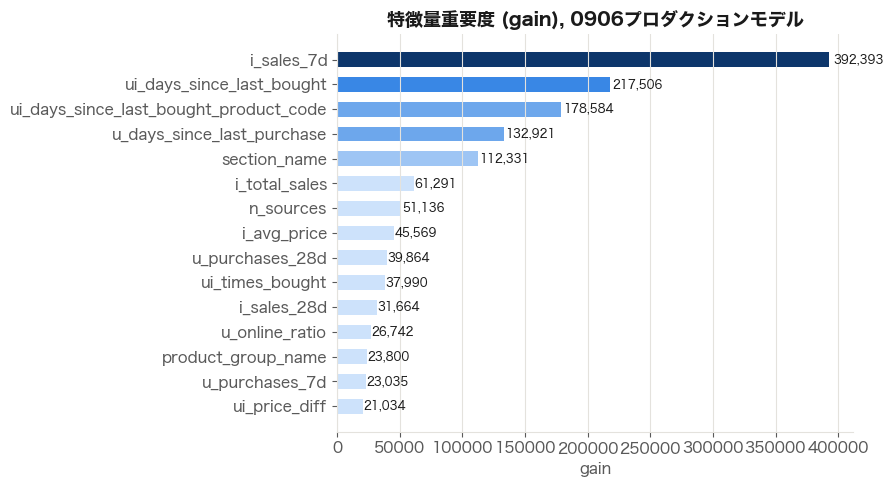

In [13]:
import pickle

with open(os.path.join(MODELS_DIR, "model_20260906_0924_ranker.pkl"), "rb") as f:
    payload = pickle.load(f)
fi = pd.DataFrame({
    "feature": payload["feature_cols"],
    "gain": payload["model"].booster_.feature_importance(importance_type="gain"),
}).sort_values("gain", ascending=False).head(15).iloc[::-1]

fig, ax = plt.subplots(figsize=(9, 5))
norm = fi["gain"] / fi["gain"].max()
colors = [SEQ_BLUE[min(6, int(n * 6))] for n in norm]
bars = ax.barh(fi["feature"], fi["gain"], color=colors, height=0.6)
for b, v in zip(bars, fi["gain"]):
    ax.text(v * 1.01, b.get_y() + b.get_height() / 2, f"{v:,.0f}", va="center", fontsize=8.5)
ax.set_title("特徴量重要度 (gain), 0906プロダクションモデル")
ax.set_xlabel("gain")
ax.grid(axis="x")
fig.tight_layout()
savefig(fig, "feature_importance_0906.png")
plt.show()

---
# 6. 総括: 何がうまくいき、何がうまくいかなかったか

各実験をその時点の比較基準(多くは直前の最良モデル)対比のPublic/Private LB変化率で整理。
正の値(青)=改善、負の値(赤)=悪化。

saved: ../02_output/report_figures/win_loss_summary.png


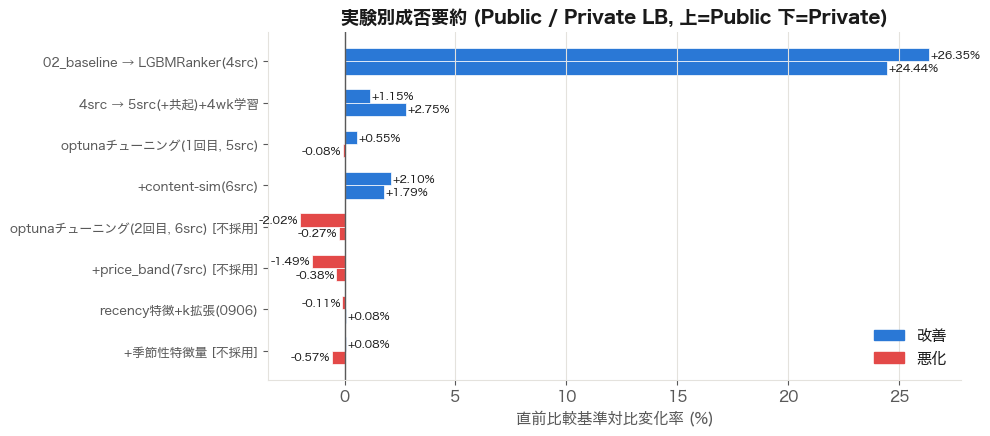

In [14]:
summary = pd.DataFrame([
    {"exp": "02_baseline → LGBMRanker(4src)", "public_delta": (0.02527/0.02000-1)*100, "private_delta": (0.02505/0.02013-1)*100},
    {"exp": "4src → 5src(+共起)+4wk学習", "public_delta": (0.02556/0.02527-1)*100, "private_delta": (0.02574/0.02505-1)*100},
    {"exp": "optunaチューニング(1回目, 5src)", "public_delta": (0.02570/0.02556-1)*100, "private_delta": (0.02572/0.02574-1)*100},
    {"exp": "+content-sim(6src)", "public_delta": (0.02624/0.02570-1)*100, "private_delta": (0.02618/0.02572-1)*100},
    {"exp": "optunaチューニング(2回目, 6src) [不採用]", "public_delta": (0.02571/0.02624-1)*100, "private_delta": (0.02611/0.02618-1)*100},
    {"exp": "+price_band(7src) [不採用]", "public_delta": (0.02585/0.02624-1)*100, "private_delta": (0.02608/0.02618-1)*100},
    {"exp": "recency特徴+k拡張(0906)", "public_delta": (0.02621/0.02624-1)*100, "private_delta": (0.02620/0.02618-1)*100},
    {"exp": "+季節性特徴量 [不採用]", "public_delta": (0.02623/0.02621-1)*100, "private_delta": (0.02605/0.02620-1)*100},
])

fig, ax = plt.subplots(figsize=(10, 4.5))
y = np.arange(len(summary))[::-1]
h = 0.32
for off, col, lab in [(h/2, "public_delta", "Public LB"), (-h/2, "private_delta", "Private LB")]:
    colors = [DIVERGE_POS if v >= 0 else DIVERGE_NEG for v in summary[col]]
    bars = ax.barh(y + off, summary[col], height=h, color=colors,
                    edgecolor="white", linewidth=0.5)
    for b, v in zip(bars, summary[col]):
        ax.text(v + (0.06 if v >= 0 else -0.06), b.get_y() + b.get_height() / 2, f"{v:+.2f}%",
                va="center", ha="left" if v >= 0 else "right", fontsize=8)
ax.axvline(0, color=TEXT_SECONDARY, linewidth=1)
ax.set_yticks(y)
ax.set_yticklabels(summary["exp"], fontsize=9)
ax.set_xlabel("直前比較基準対比変化率 (%)")
ax.set_title("実験別成否要約 (Public / Private LB, 上=Public 下=Private)")
handles = [plt.Rectangle((0,0),1,1, color=DIVERGE_POS), plt.Rectangle((0,0),1,1, color=DIVERGE_NEG)]
ax.legend(handles, ["改善", "悪化"], loc="lower right", frameon=False)
ax.grid(axis="x")
fig.tight_layout()
savefig(fig, "win_loss_summary.png")
plt.show()

---
## まとめ

- **確実に効いたもの**: ルールベース → 2段構成(候補生成+LGBMRanker)への転換(+26%)、候補ソースを6個に拡張、
  recency特徴量+候補k拡張(0906、歴代Private LB最高)
- **backtestは改善したが実際には棄却したもの**: optunaハイパーパラメータチューニング(2回)、価格帯フィルタ候補(G)、
  季節性特徴量(多週検証まで通過したがPrivate LB悪化)
- **本日作ったもの**: 再学習せず複数のheld-out週で既存モデルを再検証する `multi_week_eval.py`
  (`08_multi_week_backtest.ipynb`) — 単一週backtestの過剰最適化をある程度フィルタできるが、
  held-out週が季節的に分散していないと依然として見逃し得る(季節性特徴量の事例で確認)
- **次の課題**: 季節的により分散したheld-out構成、Private LB規模に準じた検証方法の模索
  (`00_md/pipeline_build_log.md` 8節)